# Order Book Depth & Liquidity Heatmap

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Two views of market microstructure. The depth chart shows a single moment: the cumulative size of buy orders (bids) below the price and sell orders (asks) above it, so the spread and the slope of the "walls" show how much can trade before the price moves. The liquidity heatmap shows resting order size at every price level over time, with the traded mid-price on top, so persistent walls, pulled orders and price reactions at liquidity become visible.

## When to use

- Explain liquidity, spread and market impact to traders or execution analysts
- Spot large resting orders (support/resistance "walls") and whether price respects them
- Compare liquidity across venues or times of day

## Avoid when

- The audience only needs price direction (use a price chart)
- The data is aggregated to daily bars (microstructure detail is lost)
- Order-book data is unreliable or spoofed (the chart will look authoritative anyway)

## Alternatives

- Bid-ask spread over time (line chart)
- Volume profile (volume traded at each price)

## Design tips

- Bids blue, asks orange, consistently across both panels
- Use one sequential hue for the heatmap and a log or clipped scale (a few huge orders dominate)
- Keep the price axes identical between the two panels

## Example

A simulated limit-order book for a stock trading around $100: one snapshot plus 240 one-minute snapshots, with two large resting walls (bids near $99.00, asks near $101.00). Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.colors import LinearSegmentedColormap, PowerNorm

### Data

In [2]:
rng = np.random.default_rng(3)
tick = 0.05
levels = np.round(np.arange(97.0, 103.0 + tick / 2, tick), 2)
n_t = 240
# mid-price: random walk that is capped near the $101 ask wall until minute 170
mid = np.empty(n_t)
mid[0] = 100.0
for t in range(1, n_t):
    step = rng.normal(0.004, 0.06)
    nxt = mid[t - 1] + step
    if t < 170 and nxt > 100.92:
        nxt = 100.92 - abs(rng.normal(0, 0.08))
    mid[t] = nxt
mid = np.round(mid / tick) * tick
book = np.zeros((len(levels), n_t))
for t in range(n_t):
    dist = np.abs(levels - mid[t])
    size = rng.gamma(2.0, 40, len(levels)) * np.exp(-dist / 1.2)
    size[np.isclose(levels, 99.00)] += 1500                    # persistent bid wall
    if t < 175:
        size[np.isclose(levels, 101.00)] += 1800               # ask wall, pulled at minute 175
    size[np.abs(levels - mid[t]) < tick / 2] = 0               # nothing rests at the mid
    book[:, t] = size
snapshot_t = 120
bids = pd.DataFrame({"price": levels, "size": book[:, snapshot_t]}).query("price < @mid[@snapshot_t]")
asks = pd.DataFrame({"price": levels, "size": book[:, snapshot_t]}).query("price > @mid[@snapshot_t]")
asks.head()

,price,size
66,100.30,11.475552
67,100.35,61.825671
68,100.40,73.136796
69,100.45,22.289260
70,100.50,29.646498


### Plot

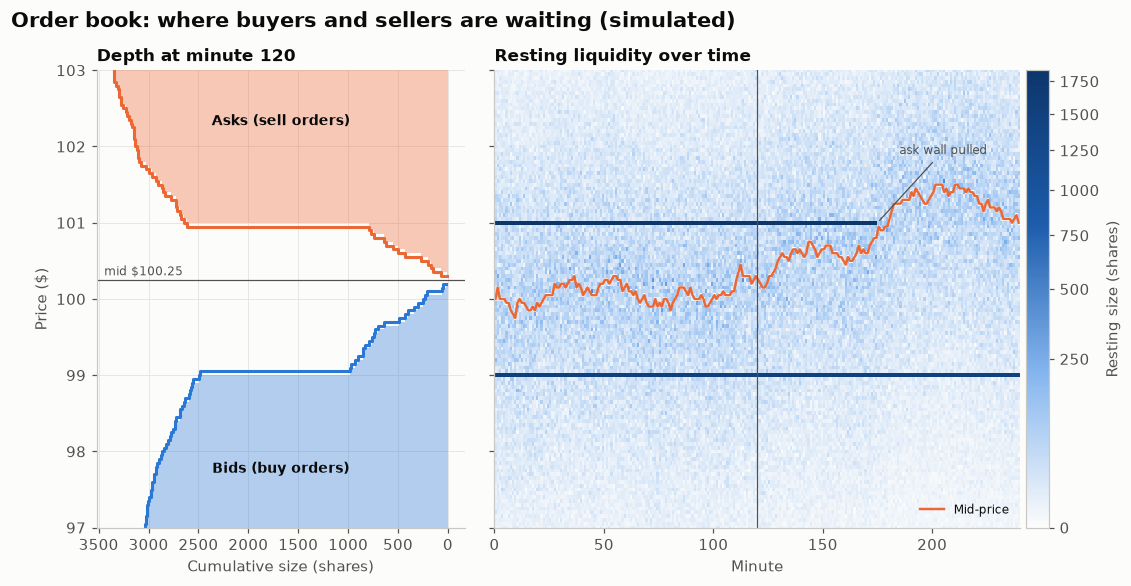

In [3]:
fig, (ax_d, ax_h) = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True,
                                 gridspec_kw={"width_ratios": [1, 1.7], "wspace": 0.06})
b = bids.sort_values("price", ascending=False)
a = asks.sort_values("price")
ax_d.fill_betweenx(b["price"], 0, b["size"].cumsum(), step="post", color=PALETTE[0], alpha=0.35, linewidth=0)
ax_d.step(b["size"].cumsum(), b["price"], where="post", color=PALETTE[0], label="Bids (buy orders)")
ax_d.fill_betweenx(a["price"], 0, a["size"].cumsum(), step="post", color=PALETTE[1], alpha=0.35, linewidth=0)
ax_d.step(a["size"].cumsum(), a["price"], where="post", color=PALETTE[1], label="Asks (sell orders)")
ax_d.axhline(mid[snapshot_t], color="#52514e", linewidth=0.8)
ax_d.annotate(f"mid ${mid[snapshot_t]:.2f}", (0.02, mid[snapshot_t]), xycoords=("axes fraction", "data"),
              xytext=(0, 3), textcoords="offset points", ha="left", fontsize=8, color="#52514e")
ax_d.invert_xaxis()
ax_d.set_xlabel("Cumulative size (shares)")
ax_d.set_ylabel("Price ($)")
ax_d.set_title(f"Depth at minute {snapshot_t}", fontsize=11)
ax_d.text(0.5, 0.12, "Bids (buy orders)", transform=ax_d.transAxes, ha="center", fontsize=9, fontweight="bold")
ax_d.text(0.5, 0.88, "Asks (sell orders)", transform=ax_d.transAxes, ha="center", fontsize=9, fontweight="bold")

cmap = LinearSegmentedColormap.from_list("liq", ["#fcfcfb", "#86b6ef", "#1c5cab", "#0d366b"])
im = ax_h.pcolormesh(np.arange(n_t + 1), np.r_[levels - tick / 2, levels[-1] + tick / 2], book,
                     cmap=cmap, norm=PowerNorm(0.5, vmin=0, vmax=np.percentile(book, 99.7)), shading="flat")
ax_h.plot(np.arange(n_t) + 0.5, mid, color=PALETTE[1], linewidth=1.6, label="Mid-price")
ax_h.axvline(snapshot_t, color="#52514e", linewidth=0.8)
ax_h.annotate("ask wall pulled", (175, 101.0), xytext=(185, 101.9), fontsize=8, color="#52514e",
              arrowprops=dict(arrowstyle="-", color="#52514e", linewidth=0.8))
ax_h.set_ylim(levels[0], levels[-1])
ax_h.set_xlabel("Minute")
ax_h.set_title("Resting liquidity over time", fontsize=11)
ax_h.grid(False)
ax_h.legend(loc="lower right", fontsize=8)
fig.colorbar(im, ax=ax_h, pad=0.01, label="Resting size (shares)")
fig.suptitle("Order book: where buyers and sellers are waiting (simulated)", x=0.06, ha="left",
             fontsize=14, fontweight="bold")
plt.show()

## How to read it

Left: the gap between the blue and orange steps at the centre is the bid-ask spread, and the jumps near $99 and $101 are large resting orders. Right: darker cells mean more resting size at that price and minute. The mid-price line stays below the dark band at $101 (a large sell wall) until the wall is pulled at minute 175, then breaks straight through. The bid wall at $99 is never tested.

---
Standalone script: [`order_book_depth.py`](order_book_depth.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)